# BIOT 6900 · Module 8 Assignment — Single-Cell & Spatial Omics (AD version)
## Alzheimer's disease brain: which cells carry the Part I target, and where they sit

This is the AD version of the Module 8 starter. The original run used the course's breast-cancer data with ERBB2. This copy follows the instruction in the Module 8 walkthrough (*"run the same workflow on your own Part I disease by changing one line of the Census query"*) and sets the target to my Part I gene.

**What changed from the starter**
- **Census query:** `disease == 'Alzheimer disease' and tissue_general == 'brain'` instead of breast cancer.
- **Cell-type mapping:** `broad_type()` rewritten for brain cells (excitatory/inhibitory neurons, astrocytes, oligodendrocytes, OPCs, microglia, vascular).
- **QC:** gene-count ceiling raised from 6,000 to 10,000, because cortical neuron nuclei routinely exceed 6,000 detected genes and the original cutoff would preferentially throw out the neurons that carry HCN1.
- **Targets:** `HCN1` (Part I lead target, fpocket 0.878, ivabradine pocket), with `APOE` as a known-biology check (expected in astrocytes and microglia).
- **Spatial:** a 10x Visium section from an **AD patient**: donor T4857 (mid-stage AD), middle temporal gyrus, from GEO **GSE220442** (Chen et al., 2022). The breast-cancer section came packaged with scanpy; this one is downloaded from GEO (instructions in 2.1). The authors' own cortical-layer label for every spot (Layers 1–6, white matter) is attached, so HCN1 can be read out by layer.

- **Part 1 (single-cell):** which brain cell types express HCN1 in AD tissue?
- **Part 2 (spatial):** where does HCN1 sit in AD cortex (grey vs white matter, which layers)?

### Requirements
Environment: the course `biot6900` / Explorer environment (`scanpy`, `cellxgene-census`, `scvi-tools`, `harmonypy`, `squidpy`). Needs **Python 3.13 or earlier**. If an import fails, run the install cell once and restart the kernel.

In [1]:
# Run once only if an import below fails, then restart the kernel. Python <= 3.13.
# !pip install "cellxgene-census" "scvi-tools" harmonypy squidpy scanpy leidenalg igraph

In [2]:
import os
os.environ["NUMBA_THREADING_LAYER"] = "workqueue"   # must run before scanpy; stops torch + numba crashing the kernel

import scanpy as sc
import squidpy as sq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=80, facecolor="white")
try:
    import torch
    GPU = torch.cuda.is_available() or torch.backends.mps.is_available()   # CHANGED: starter only checked CUDA; also use Apple-silicon GPU (MPS)
    print("GPU available:", GPU)
except Exception:
    GPU = False
    print("running on CPU")
print("scanpy", sc.__version__, "| squidpy", sq.__version__)

/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


GPU available: True
scanpy 1.11.5 | squidpy 1.8.2


/var/folders/cs/q9v9wry90sld3yrkbx9l1l1m0000gn/T/ipykernel_35345/1291087591.py:19: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("scanpy", sc.__version__, "| squidpy", sq.__version__)


---
# PART 1 · Single-cell: which cells express the target

## 1.1 · Pull the Alzheimer's disease brain data
Pulls AD brain nuclei/cells from the CZ CELLxGENE Census and samples **10 whole donors** (2,000 cells each), exactly as the starter did for breast cancer. In the stable Census this query returns roughly 600k cells from 80 donors across 9 datasets and several cortical regions, so donor and dataset are partly confounded. That is the batch problem 1.3 to 1.6 are about.

In [3]:
import cellxgene_census

census = cellxgene_census.open_soma(census_version="stable")
obs = cellxgene_census.get_obs(
    census, "Homo sapiens",
    # AD VERSION — CHANGED: Census query was disease == 'breast cancer'; now Alzheimer disease, brain tissue only.
    value_filter="disease == 'Alzheimer disease' and tissue_general == 'brain' and is_primary_data == True",
    # AD VERSION — CHANGED: added dataset_id and tissue (AD donors come from 9 datasets and several brain regions).
    column_names=["soma_joinid", "donor_id", "dataset_id", "assay", "cell_type", "tissue"],
)
print(f"matching cells in the Census: {len(obs):,}")

# Sample whole donors (not scattered cells), so batch-aware steps have enough per donor.
rng = np.random.default_rng(0)
cells_per_donor = 2000
donor_sizes = obs["donor_id"].value_counts()
big_donors = donor_sizes[donor_sizes >= cells_per_donor].index.to_numpy()
donors = rng.choice(big_donors, size=min(10, len(big_donors)), replace=False)
sel = np.concatenate([
    rng.choice(obs.loc[obs["donor_id"] == d, "soma_joinid"].to_numpy(), size=cells_per_donor, replace=False)
    for d in donors
])
adata = cellxgene_census.get_anndata(
    census, "Homo sapiens", obs_coords=np.sort(sel),
    # AD VERSION — CHANGED: added dataset_id and tissue here too.
    obs_column_names=["donor_id", "dataset_id", "assay", "cell_type", "tissue", "disease", "sex"],
    var_column_names=["feature_id", "feature_name"],
)
census.close()
adata.var_names = adata.var["feature_name"].astype(str)
adata.var_names_make_unique()

# AD VERSION — CHANGED: broad_type() rewritten for brain cell types (neurons, glia, OPC, vascular).
# AD VERSION — REMOVED: the breast-tissue categories (T, B, NK, Monocyte, DC, Macrophage, Epithelial/Tumor,
# AD VERSION — Fibroblast, Endothelial) and my 'malignant' T-cell fix, since there are no tumour cells in brain.
def broad_type(ct):
    """Collapse Census brain cell-type labels into broad classes. Order matters:
    specific labels (e.g. 'oligodendrocyte precursor cell') are checked before general ones."""
    ct = str(ct).lower()
    if "glutamatergic" in ct or "excitatory" in ct or "pyramidal" in ct: return "Excitatory neuron"
    if "gabaergic" in ct or "inhibitory" in ct or "interneuron" in ct: return "Inhibitory neuron"
    if "neuron" in ct: return "Neuron (unspecified)"
    if "precursor" in ct or "opc" in ct: return "OPC"
    if "oligodendrocyte" in ct: return "Oligodendrocyte"
    if "astrocyte" in ct: return "Astrocyte"
    if "microglia" in ct or "macrophage" in ct or "monocyte" in ct: return "Microglia/Macrophage"
    if any(k in ct for k in ["endothelial", "pericyte", "smooth muscle", "fibroblast", "leptomeningeal"]):
        return "Vascular"
    if "t cell" in ct or "b cell" in ct or "leukocyte" in ct: return "Lymphocyte"
    return "Other"

adata.obs["cell_type_broad"] = adata.obs["cell_type"].map(broad_type).astype("category")
# AD VERSION — CHANGED: was a cells/donors count line; now prints the AnnData summary, cell types, and tissue regions sampled.
print(adata)
print(adata.obs["cell_type_broad"].value_counts().to_string())
print("\ntissues sampled:\n", adata.obs["tissue"].value_counts().to_string())

The "stable" release is currently 2025-11-08. Specify 'census_version="2025-11-08"' in future calls to open_soma() to ensure data consistency.


matching cells in the Census: 608,235


/opt/anaconda3/envs/biot6900/lib/python3.11/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/anaconda3/envs/biot6900/lib/python3.11/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


AnnData object with n_obs × n_vars = 20000 × 61497
    obs: 'donor_id', 'dataset_id', 'assay', 'cell_type', 'tissue', 'disease', 'sex', 'cell_type_broad'
    var: 'feature_id', 'feature_name'
cell_type_broad
Excitatory neuron       8010
Neuron (unspecified)    3306
Oligodendrocyte         2955
Inhibitory neuron       2749
Astrocyte               1379
Microglia/Macrophage     823
OPC                      514
Vascular                 264

tissues sampled:
 tissue
prefrontal cortex                               4463
Brodmann (1909) area 9                          3364
superior frontal gyrus                          3054
entorhinal cortex                               2946
Brodmann (1909) area 17                         2290
Brodmann (1909) area 7                          1883
insular cortex                                  1020
primary visual cortex                            653
Brodmann (1909) area 4                           327
parotid gland                                      0
pari

/var/folders/cs/q9v9wry90sld3yrkbx9l1l1m0000gn/T/ipykernel_35345/1360562457.py:31: UserWarning: Suffix used (-[0-9]+) to deduplicate index values may make index values difficult to interpret. There values with a similar suffixes in the index. Consider using a different delimiter by passing `join={delimiter}`. Example key collisions generated by the make_index_unique algorithm: ['SNORD115-1', 'SNORD115-2', 'SNORD115-3', 'SNORD115-4', 'SNORD115-5']
  adata.var_names_make_unique()


## 1.2 · Standard pipeline  *(provided)*
QC, normalize, batch-aware highly variable genes, PCA. The raw counts are kept for scVI and for marker plots.

In [4]:
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.filter_cells(adata, min_genes=200)
# AD VERSION — CHANGED: n_genes ceiling raised from 6000 to 10000: cortical neuron nuclei often detect >6000 genes, and the
# starter's cutoff would preferentially remove the neurons that carry HCN1.
adata.layers["counts"] = adata.X.copy()
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
adata = adata[(adata.obs.n_genes_by_counts < 10000) & (adata.obs.pct_counts_mt < 15)].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata
sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat_v3", layer="counts", batch_key="donor_id", span=0.5)
adata = adata[:, adata.var.highly_variable].copy()
sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, svd_solver="arpack")
print("cells after QC:", adata.n_obs)

/opt/anaconda3/envs/biot6900/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


cells after QC: 19600


## 1.3 · The batch problem
The unintegrated embedding is computed for you.

In [5]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30, use_rep="X_pca")
sc.tl.umap(adata)
adata.obsm["X_umap_unint"] = adata.obsm["X_umap"].copy()

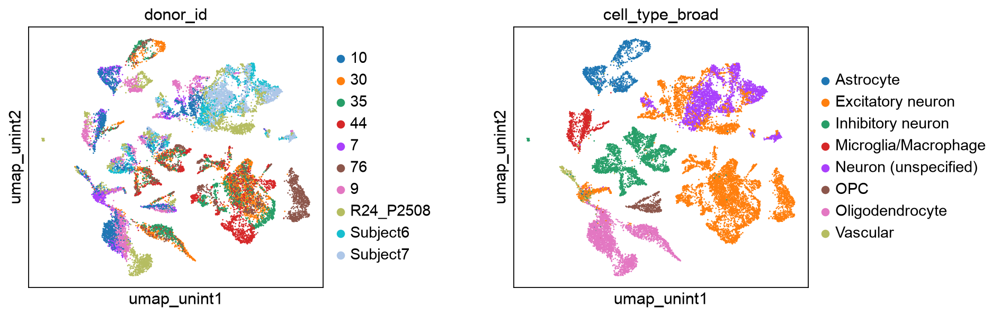

In [6]:
# plot the unintegrated UMAP colored by donor and by cell type.
sc.pl.embedding(adata, basis="umap_unint", color=["donor_id", "cell_type_broad"], wspace=0.5)


## 1.4 · Integrate with scVI  *(provided, GPU step)*

In [7]:
import scvi
scvi.model.SCVI.setup_anndata(adata, layer="counts", batch_key="donor_id")
vae = scvi.model.SCVI(adata, n_latent=30)
vae.train(max_epochs=(200 if GPU else 60), accelerator=("gpu" if GPU else "cpu"))
adata.obsm["X_scVI"] = vae.get_latent_representation()
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_scVI")
sc.tl.umap(adata)
adata.obsm["X_umap_scvi"] = adata.obsm["X_umap"].copy()
print("scVI done")

/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch/Jax operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.


Training:   0%|          | 0/200 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=200` reached.


scVI done


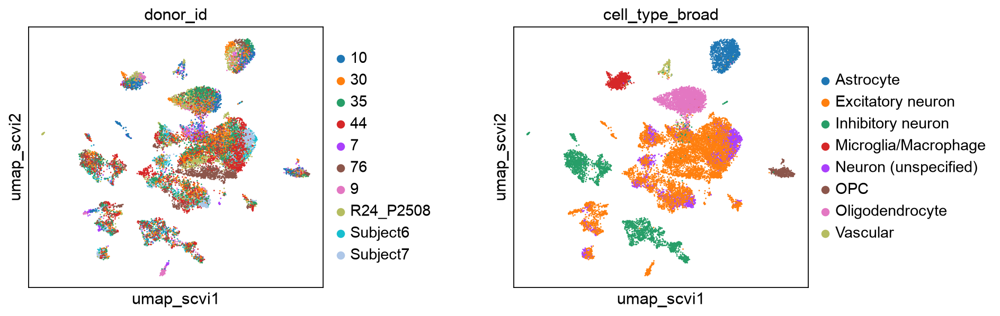

In [8]:
# plot the scVI UMAP colored by donor and by cell type. Did the donors mix?
sc.pl.embedding(adata, basis="umap_scvi", color=["donor_id", "cell_type_broad"], wspace=0.5)


## 1.5 · Harmony, a fair baseline  *(provided)*

In [9]:
import harmonypy
ho = harmonypy.run_harmony(adata.obsm["X_pca"].astype(np.float64), adata.obs, "donor_id")
Z = np.asarray(ho.Z_corr)
adata.obsm["X_pca_harmony"] = Z if Z.shape[0] == adata.n_obs else Z.T
print("Harmony done")

2026-11-23 22:22:33,889 - harmonypy - INFO - Running Harmony


2026-11-23 22:22:33,889 - harmonypy - INFO -   Parameters:


2026-11-23 22:22:33,889 - harmonypy - INFO -     max_iter_harmony: 10


2026-11-23 22:22:33,889 - harmonypy - INFO -     max_iter_kmeans: 4


2026-11-23 22:22:33,889 - harmonypy - INFO -     epsilon_cluster: 0.001


2026-11-23 22:22:33,889 - harmonypy - INFO -     epsilon_harmony: 0.01


... (15 outputs left out)

2026-11-23 22:22:33,962 - harmonypy - INFO - Iteration 5 of 10


2026-11-23 22:22:33,973 - harmonypy - INFO - Iteration 6 of 10


2026-11-23 22:22:33,985 - harmonypy - INFO - Converged after 6 iterations


Harmony done


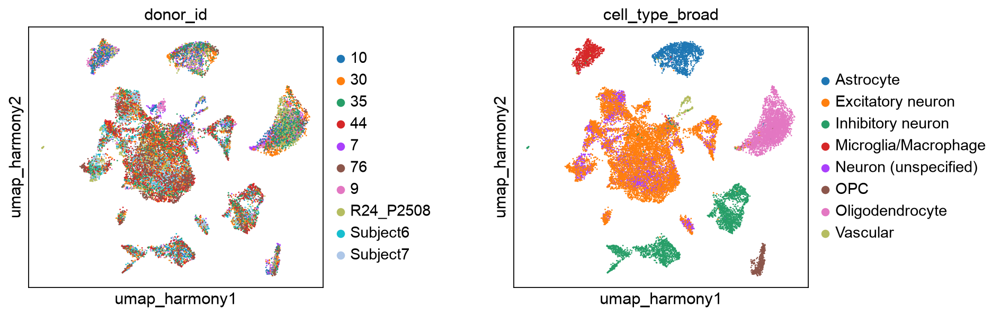

In [10]:
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_pca_harmony")
sc.tl.umap(adata)
adata.obsm["X_umap_harmony"] = adata.obsm["X_umap"].copy()
sc.pl.embedding(adata, basis="umap_harmony", color=["donor_id", "cell_type_broad"], wspace=0.5)

## 1.6 · Judge the fix
How well each method (no integration, Harmony, scVI) mixes donors and preserves cell types.

In [11]:
from sklearn.metrics import silhouette_score
# for each embedding, score batch mixing (by donor_id, lower is better)
#       and biology preservation (by cell_type_broad, higher is better).
idx = rng.choice(adata.n_obs, size=min(5000, adata.n_obs), replace=False)
reps = {"No integration": "X_pca", "Harmony": "X_pca_harmony", "scVI": "X_scVI"}
for name, key in reps.items():
    emb = adata.obsm[key][idx]
    batch = silhouette_score(emb, adata.obs["donor_id"].values[idx])
    bio   = silhouette_score(emb, adata.obs["cell_type_broad"].values[idx])
    print(name, round(batch,3), round(bio,3))


No integration -0.034 0.16


Harmony -0.096 0.159


scVI -0.038 0.036


## 1.7 · Annotate and confirm with markers
The broad cell types are already assigned; the labeled map and canonical markers confirm them.

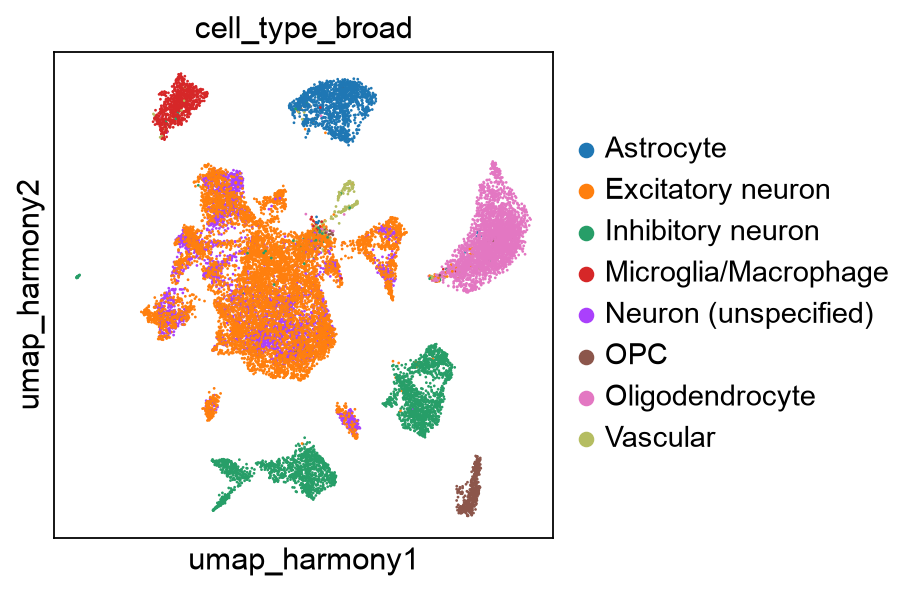

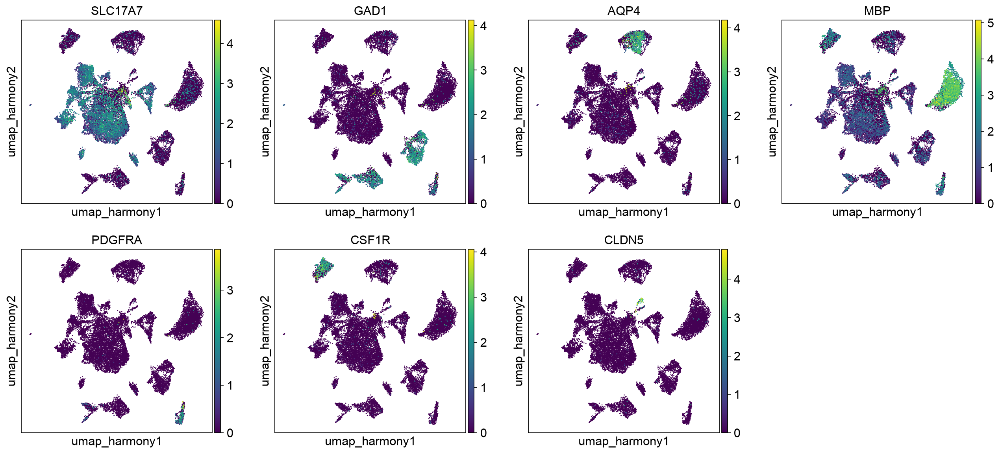

In [12]:
# AD VERSION — CHANGED: breast/immune markers (CD3D, MS4A1, CD14, EPCAM, PECAM1, COL1A1) replaced
# AD VERSION — with the brain markers below; ncols 3 -> 4.
# Labeled map plus canonical brain markers to confirm the broad labels.
# SLC17A7 excitatory neurons, GAD1 inhibitory neurons, AQP4 astrocytes, MBP oligodendrocytes,
# PDGFRA OPCs, CSF1R microglia, CLDN5 endothelium.
sc.pl.embedding(adata, basis="umap_harmony", color="cell_type_broad")
markers = [g for g in ["SLC17A7", "GAD1", "AQP4", "MBP", "PDGFRA", "CSF1R", "CLDN5"] if g in adata.raw.var_names]
sc.pl.embedding(adata, basis="umap_harmony", color=markers, use_raw=True, ncols=4)

## 1.8 · Locate your target in the cell types
Target is **HCN1**, the Part I lead (Module 4 fpocket 0.878; ivabradine pocket confirmed against 8Y60; PageRank-tied third in the Module 7 graph). **APOE** is plotted alongside as a known-gene check: if the pipeline is sound it should land in astrocytes and microglia, not neurons.

Besides the UMAP, the cell below reports the **fraction of cells expressing** each gene and the **mean expression** per broad cell type, so the answer is a number rather than a reading of colours.

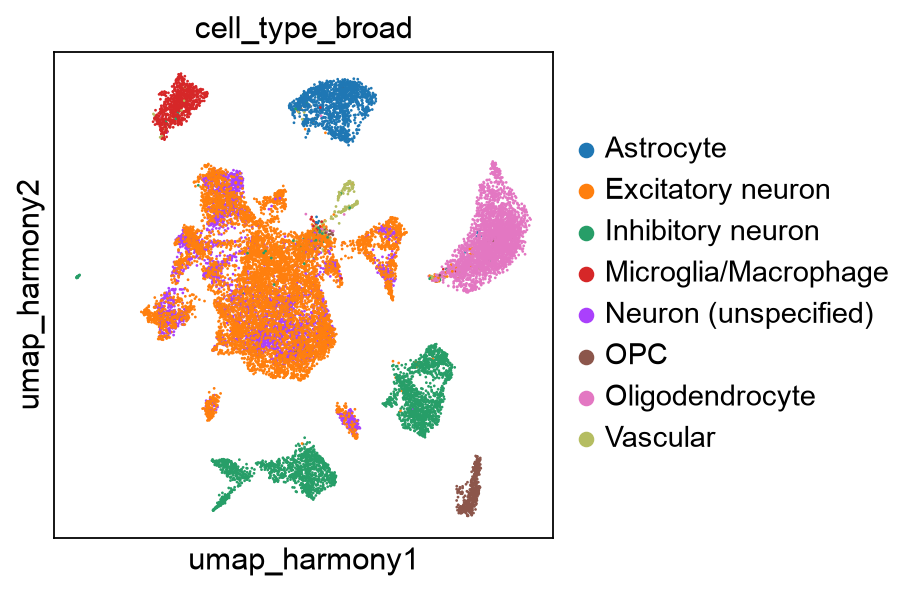

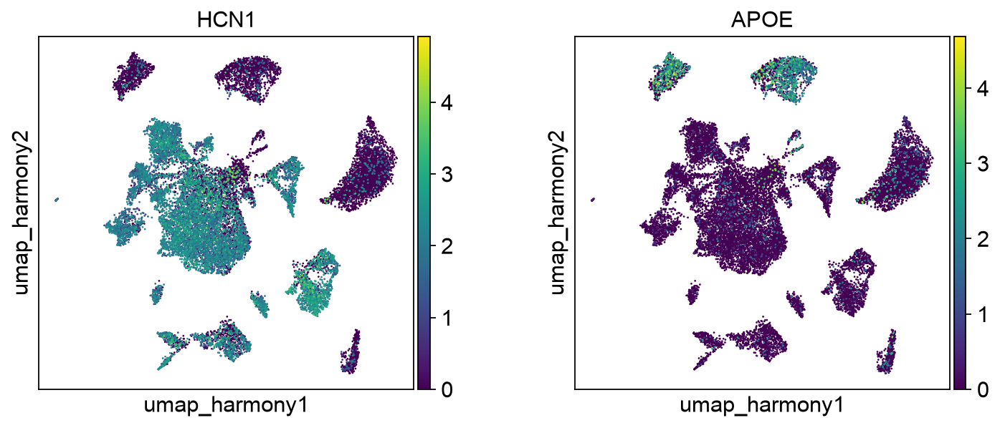

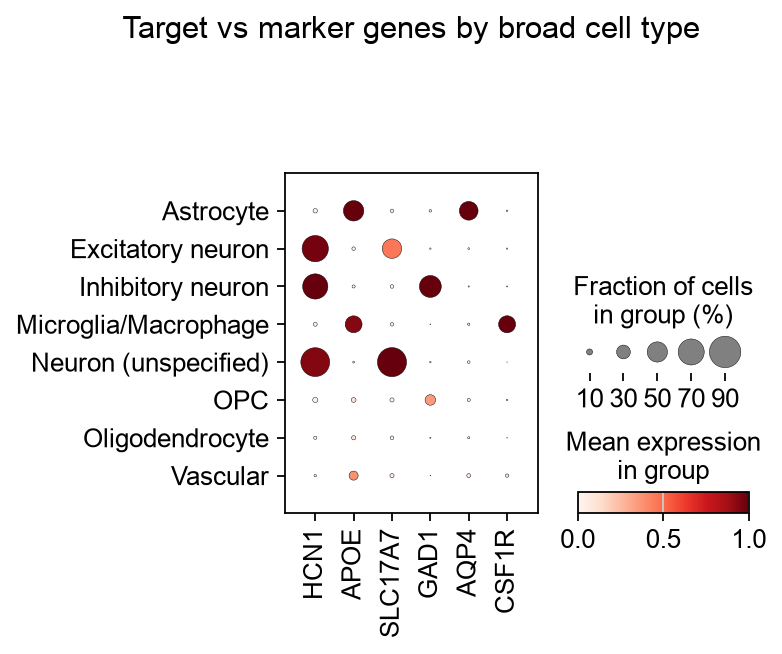

           cell_type  n_cells  HCN1_pct_expressing  HCN1_mean_expr  APOE_pct_expressing  APOE_mean_expr
Neuron (unspecified)     3278                 80.3           1.388                  2.0           0.020
   Excitatory neuron     7821                 71.0           1.429                  4.8           0.062
   Inhibitory neuron     2682                 67.2           1.467                  4.1           0.060
                 OPC      496                  8.1           0.123                  7.3           0.133
           Astrocyte     1377                  6.5           0.113                 50.5           1.074
Microglia/Macrophage      809                  5.6           0.122                 39.3           1.010
     Oligodendrocyte     2939                  4.3           0.085                  6.1           0.115
            Vascular      198                  3.0           0.078                 17.2           0.426


In [13]:
# AD VERSION — CHANGED: TARGET was ERBB2; now HCN1 (Part I lead target).
TARGET = "HCN1"          # Part I lead target
# AD VERSION — NEW: APOE as a known-gene control (should land in astrocytes/microglia).
CONTROL = "APOE"         # known AD gene, expected in astrocytes/microglia
genes = [g for g in [TARGET, CONTROL] if g in adata.raw.var_names]
# AD VERSION — CHANGED: plots the cell-type map, then HCN1 and APOE (was ERBB2 alone). The cell-type map
# is drawn on its own so its long legend does not overlap the gene panels.
sc.pl.embedding(adata, basis="umap_harmony", color="cell_type_broad")
sc.pl.embedding(adata, basis="umap_harmony", color=genes, use_raw=True, ncols=2, wspace=0.3)
# AD VERSION — NEW: dot plot of targets vs cell-type markers.
sc.pl.dotplot(adata, genes + ["SLC17A7", "GAD1", "AQP4", "CSF1R"], groupby="cell_type_broad", use_raw=True,
              standard_scale="var", title="Target vs marker genes by broad cell type")

# AD VERSION — NEW: per-cell-type % expressing and mean expression table, saved to images/.
# Quantify: fraction of cells with any expression, and mean log-normalised expression, per cell type
X = adata.raw[:, genes].X
X = X.toarray() if hasattr(X, "toarray") else np.asarray(X)
ct = adata.obs["cell_type_broad"].values
rows = []
for c in adata.obs["cell_type_broad"].cat.categories:
    m = ct == c
    r = {"cell_type": c, "n_cells": int(m.sum())}
    for j, g in enumerate(genes):
        r[f"{g}_pct_expressing"] = round(100 * float((X[m, j] > 0).mean()), 1)
        r[f"{g}_mean_expr"] = round(float(X[m, j].mean()), 3)
    rows.append(r)
target_tbl = pd.DataFrame(rows).sort_values(f"{TARGET}_pct_expressing", ascending=False)
print(target_tbl.to_string(index=False))

os.makedirs("images", exist_ok=True)
target_tbl.to_csv("images/module8_ad_target_expression_by_celltype.csv", index=False)

---
# PART 2 · Spatial: where those cells sit in the cortex

## 2.1 · Load an AD patient's Visium section
Middle temporal gyrus (MTG) from donor **T4857**, diagnosed with mid-stage AD, from GEO **GSE220442**: 10x Visium on 3 AD and 3 control donors (Chen et al., 2022, *Acta Neuropathologica Communications*). MTG is a region affected early in AD.

**Data (committed to the repo, about 28 MB):** `data/GSE220442_T4857/` holds just what this notebook reads: the donor's `filtered_feature_bc_matrix.h5`, the four `spatial/` files Space Ranger needs (tissue positions, scale factors, high- and low-resolution images) and the series' spot metadata `GSE220442_metadata.csv.gz`. They come from `GSE220442_counts_and_images.tar.gz` and `GSE220442_metadata.csv.gz` on https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE220442 (T4857's files were gunzipped). AD donors in this series are `2_3`, `2_8` and `T4857`; controls are `1_1`, `2_5` and `18_64`.

The metadata file carries the authors' layer annotation for each spot. It is joined on barcode so HCN1 can be reported per cortical layer.

In [14]:
# AD VERSION — CHANGED: the breast-cancer section came from sc.datasets.visium_sge(); this is an AD patient's
# AD VERSION — MTG section (donor T4857, mid-stage AD) read from the GEO GSE220442 download with sc.read_visium.
spatial = sc.read_visium("data/GSE220442_T4857")
spatial.var_names_make_unique()

# AD VERSION — NEW: attach the authors' per-spot cortical layer and diagnosis from the GEO metadata.
# Metadata barcodes end in "-T4857"; Space Ranger's end in "-1".
meta = pd.read_csv("data/GSE220442_T4857/GSE220442_metadata.csv.gz")
meta = meta[meta.patientID == "T4857"].copy()
meta.index = meta["Unnamed: 0"].str.replace("-T4857", "-1", regex=False)
spatial.obs["layer"] = meta.reindex(spatial.obs_names)["Layer"].astype("category")
spatial.obs["diagnosis"] = meta.reindex(spatial.obs_names)["stage"].values
print(spatial)
print("spots x genes:", spatial.shape)
print("diagnosis:", spatial.obs["diagnosis"].value_counts().to_dict())
print("spots with an author layer label:", int(spatial.obs["layer"].notna().sum()))

/var/folders/cs/q9v9wry90sld3yrkbx9l1l1m0000gn/T/ipykernel_35345/2404152688.py:3: FutureWarning: Use `squidpy.read.visium` instead.
  spatial = sc.read_visium("data/GSE220442_T4857")


AnnData object with n_obs × n_vars = 4832 × 36601
    obs: 'in_tissue', 'array_row', 'array_col', 'layer', 'diagnosis'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'
spots x genes: (4832, 36601)
diagnosis: {'Mid-AD': 4832}
spots with an author layer label: 4832


/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


## 2.2 · Pipeline and clustering  *(provided)*

In [15]:
spatial.var["mt"] = spatial.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(spatial, qc_vars=["mt"], inplace=True)
sc.pp.filter_cells(spatial, min_counts=500)
spatial.layers["counts"] = spatial.X.copy()
sc.pp.normalize_total(spatial, target_sum=1e4)
sc.pp.log1p(spatial)
spatial.raw = spatial
sc.pp.highly_variable_genes(spatial, n_top_genes=2000)
sc.pp.pca(spatial)
sc.pp.neighbors(spatial)
sc.tl.leiden(spatial, resolution=0.6, key_added="cluster")
print("spatial domains found:", spatial.obs["cluster"].nunique())

/var/folders/cs/q9v9wry90sld3yrkbx9l1l1m0000gn/T/ipykernel_35345/4117200164.py:11: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(spatial, resolution=0.6, key_added="cluster")


spatial domains found: 3


## 2.3 · Spatial domains on the tissue
Draw the clusters back on the tissue and relate them to cortical anatomy. Domain IDs are not known in advance, so the cell below picks, for each anatomical marker, the domain with the highest mean expression of it. The authors' layer labels are then used as an independent check on the domains.

mean marker expression by domain:
           MBP  SNAP25  CUX2  PCP4
cluster                          
0        2.23    2.93  0.19  0.22
1        3.43    2.81  0.08  0.33
2        2.13    2.58  0.14  0.20


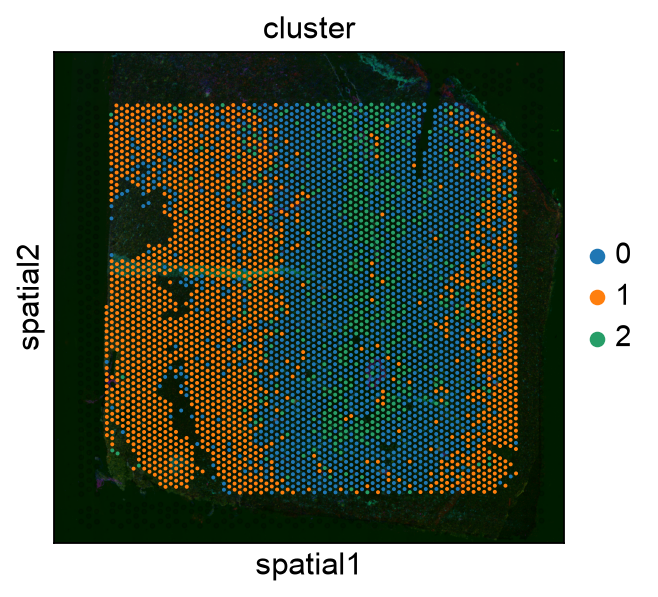

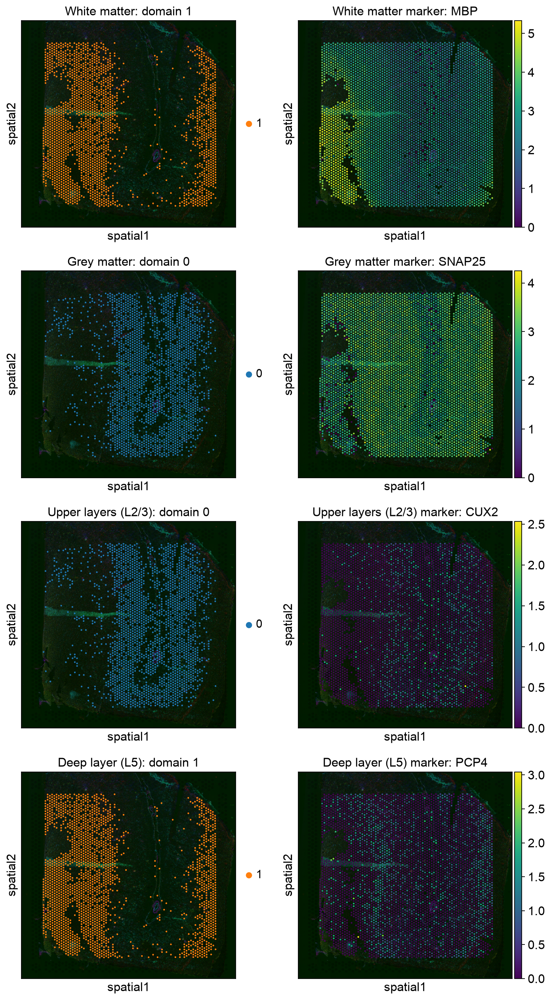

fraction of each domain's spots in each author layer:
 layer    Layer 1  Layer 2  Layer 3  Layer 4  Layer 5  Layer 6  Noise  White Matter
cluster                                                                           
0           0.11     0.20     0.46     0.10     0.06     0.02    0.0          0.04
1           0.01     0.00     0.04     0.10     0.31     0.20    0.0          0.33
2           0.47     0.24     0.15     0.06     0.05     0.01    0.0          0.01


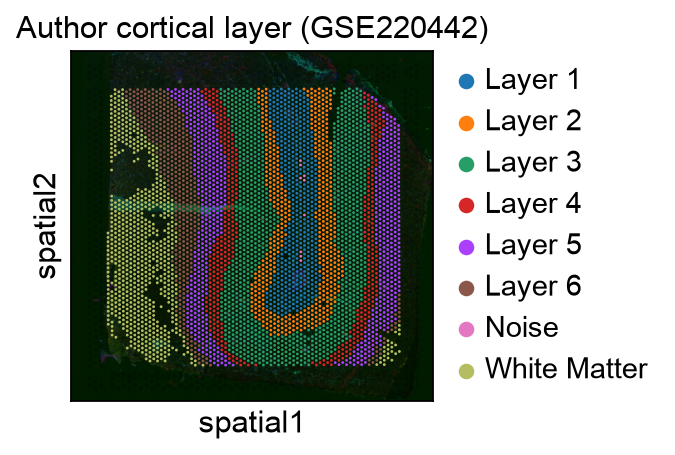

In [16]:
# AD VERSION — REMOVED: the starter's 'TODO: plot the clusters on the tissue image.' comment.
sq.pl.spatial_scatter(spatial, color="cluster")

# AD VERSION — CHANGED: the breast version hard-coded tumour/stroma/immune domains (2+4, 1, 0) with
# AD VERSION — KRT8/COL1A1/IGKC. Brain domain IDs aren't known in advance, so each anatomical marker
# AD VERSION — now picks the domain with the highest mean expression.
# Anatomical markers: MBP = myelin (white matter); SNAP25 = neurons (grey matter);
# CUX2 = upper layers L2/3; PCP4 = deep layer L5.
anat = [("White matter", "MBP"), ("Grey matter", "SNAP25"),
        ("Upper layers (L2/3)", "CUX2"), ("Deep layer (L5)", "PCP4")]
anat = [(lab, g) for lab, g in anat if g in spatial.raw.var_names]
expr = pd.DataFrame(
    {g: np.asarray(spatial.raw[:, g].X.todense()).ravel() if hasattr(spatial.raw[:, g].X, "todense")
        else np.asarray(spatial.raw[:, g].X).ravel() for _, g in anat},
    index=spatial.obs_names)
expr["cluster"] = spatial.obs["cluster"].values
# AD VERSION — NEW: mean marker expression per domain (printed and saved to images/).
cluster_means = expr.groupby("cluster", observed=True).mean()
print("mean marker expression by domain:\n", cluster_means.round(2).to_string())

fig, axes = plt.subplots(len(anat), 2, figsize=(9, 4 * len(anat)))
for (label, gene), (ax_dom, ax_gene) in zip(anat, axes):
    best = str(cluster_means[gene].idxmax())
    sq.pl.spatial_scatter(spatial, color="cluster", groups=[best], ax=ax_dom,
                          title=f"{label}: domain {best}")
    sq.pl.spatial_scatter(spatial, color=gene, ax=ax_gene, title=f"{label} marker: {gene}")
plt.tight_layout()
plt.show()

os.makedirs("images", exist_ok=True)
cluster_means.round(3).to_csv("images/module8_ad_spatial_domain_marker_means.csv")

# AD VERSION — NEW: the authors' layer annotation on the tissue, and how each Leiden domain maps onto it.
sq.pl.spatial_scatter(spatial, color="layer", title="Author cortical layer (GSE220442)")
dom_vs_layer = pd.crosstab(spatial.obs["cluster"], spatial.obs["layer"], normalize="index").round(2)
print("fraction of each domain's spots in each author layer:\n", dom_vs_layer.to_string())
dom_vs_layer.to_csv("images/module8_ad_spatial_domain_vs_layer.csv")

## 2.4 · Spatially variable genes (Moran's I)
The spatial neighbor graph is built for you.

In [17]:
sq.gr.spatial_neighbors(spatial)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/var/folders/cs/q9v9wry90sld3yrkbx9l1l1m0000gn/T/ipykernel_35345/2129188737.py:1: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(spatial)


               I
MBP     0.824582
MT-CO1  0.544651
PLP1    0.526270
CRYAB   0.379078
TAGLN   0.298210
MOBP    0.292325
BCAS1   0.267279
CCK     0.258043


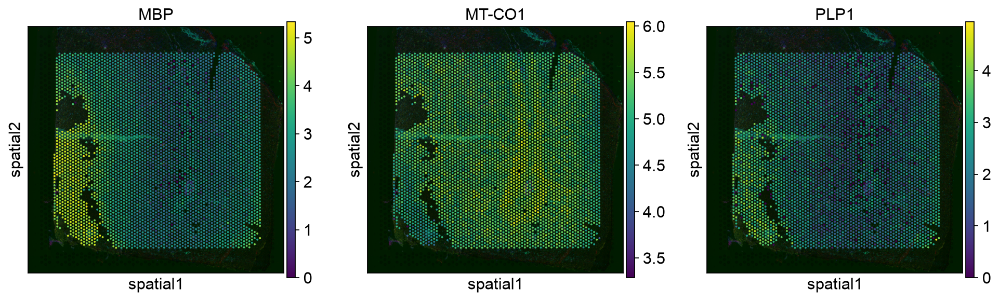

In [18]:
# AD VERSION — CHANGED: removed the starter's 'TODO:' prefix from the comment below; code unchanged.
# compute Moran's I, print the top spatially variable genes, and plot 2-3 on the tissue.

sq.gr.spatial_autocorr(spatial, mode="moran")
top = spatial.uns["moranI"].head(8); print(top[["I"]])
sq.pl.spatial_scatter(spatial, color=spatial.uns["moranI"].head(3).index.tolist())


## 2.5 · Neighborhood enrichment
Compute which domains sit next to each other more than chance. In cortex this should recover the laminar order (adjacent layers touch; white matter touches only the deepest layer).

  0%|          | 0/1000 [00:00<?, ?/s]

/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


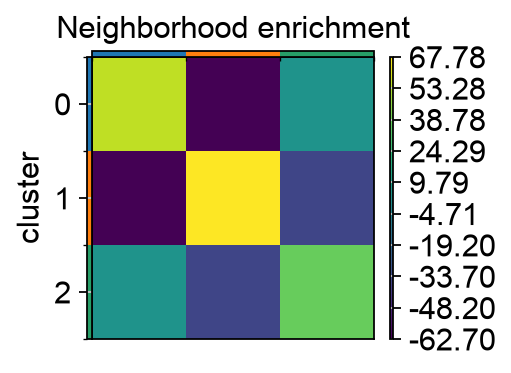

In [19]:
# AD VERSION — CHANGED: removed the starter's 'TODO:' prefix from the comment below; code unchanged.
# run and plot neighborhood enrichment across the clusters.

sq.gr.nhood_enrichment(spatial, cluster_key="cluster")
sq.pl.nhood_enrichment(spatial, cluster_key="cluster")


## 2.6 · Locate your target in the tissue
Colour the AD section by HCN1 (and APOE), then report mean expression per Leiden domain and per author-annotated cortical layer, so the answer is quantitative.

mean target expression per domain, with anatomical markers:
           HCN1   APOE   MBP  SNAP25  CUX2  PCP4
cluster                                        
0        0.312  2.500  2.23    2.93  0.19  0.22
1        0.244  2.486  3.43    2.81  0.08  0.33
2        0.229  2.760  2.13    2.58  0.14  0.20

mean target expression per author layer (AD donor T4857):
               n_spots   HCN1   APOE  HCN1_pct_spots  APOE_pct_spots
layer                                                              
Layer 1           503  0.187  2.638            14.5            98.4
Layer 2           546  0.287  2.612            36.4           100.0
Layer 3          1126  0.332  2.564            46.4           100.0
Layer 4           442  0.346  2.493            46.6            99.8
Layer 5           777  0.373  2.422            48.4           100.0
Layer 6           450  0.233  2.408            24.7            99.6
White Matter      745  0.110  2.516             7.7            91.9


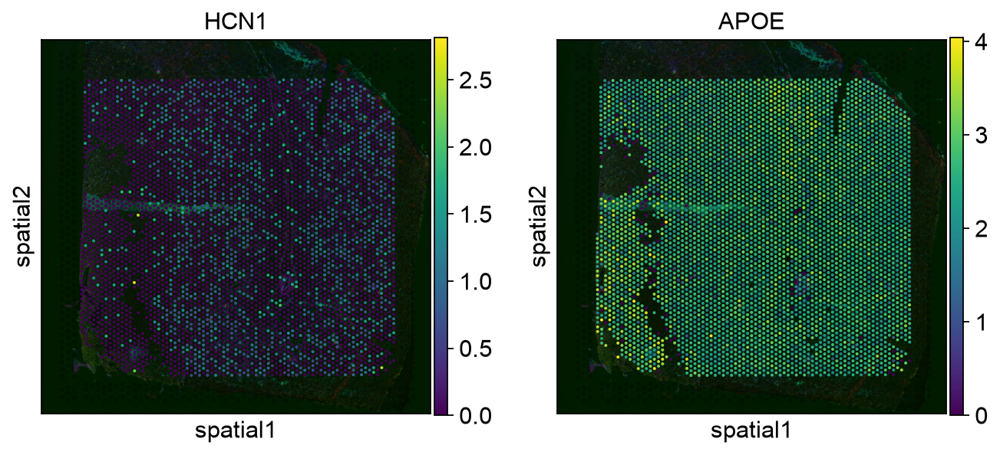

In [20]:
# AD VERSION — REMOVED: the starter's 'TODO: plot TARGET on the tissue' comment.
# AD VERSION — CHANGED: plots HCN1 and APOE (was TARGET alone).
show = [g for g in [TARGET, CONTROL] if g in spatial.raw.var_names]
if show:
    sq.pl.spatial_scatter(spatial, color=show)
    # AD VERSION — NEW: mean HCN1/APOE per spatial domain next to the anatomical markers, saved to images/.
    v = spatial.raw[:, show].X
    v = v.toarray() if hasattr(v, "toarray") else np.asarray(v)
    dom = pd.DataFrame(v, columns=show, index=spatial.obs_names)
    dom["cluster"] = spatial.obs["cluster"].values
    by_dom = dom.groupby("cluster", observed=True).mean().round(3)
    by_dom = by_dom.join(cluster_means.round(2)).sort_values(show[0], ascending=False)
    print("mean target expression per domain, with anatomical markers:\n", by_dom.to_string())
    by_dom.to_csv("images/module8_ad_spatial_target_by_domain.csv")

    # AD VERSION — NEW: mean HCN1/APOE and % of spots with any expression, per author cortical layer.
    dom["layer"] = spatial.obs["layer"].values
    lay = dom[dom.layer.notna() & (dom.layer != "Noise")]
    order = ["Layer 1", "Layer 2", "Layer 3", "Layer 4", "Layer 5", "Layer 6", "White Matter"]
    by_layer = lay.groupby("layer", observed=True)[show].mean().round(3).reindex(order)
    for g in show:
        by_layer[f"{g}_pct_spots"] = (lay.groupby("layer", observed=True)[g].apply(lambda s: (s > 0).mean() * 100)
                                      .reindex(order).round(1))
    by_layer.insert(0, "n_spots", lay.layer.value_counts().reindex(order))
    print("\nmean target expression per author layer (AD donor T4857):\n", by_layer.to_string())
    by_layer.to_csv("images/module8_ad_spatial_target_by_layer.csv")
else:
    print(TARGET, "not in this panel; pick a gene present in spatial.raw.var_names")

---
# Notes for Portfolio Deliverable 2, section 5

- Which brain cell types express HCN1 in AD tissue (Part 1), and which cortical layers of an AD patient's MTG carry it (Part 2).
- APOE as known-gene recovery: does it land in glia?
- Integration choice, justified with the silhouette scores.
- Limitations: 10 donors pooled across datasets and cortical regions; AD-only cells (no matched controls), so this shows *where* HCN1 is expressed, not whether it changes in AD; the Visium section is one AD donor (MTG), so there is no within-section control; the same series has 3 control donors that could be added. Spot resolution mixes cell types.